# BankUnited industry fit exploration

Map industry research of  metro business activity: priorities, industry scale, growth, specialization, selected comparison markets, coverage, and priority sensitivity. Default snapshot: **2023**; growth window: **2019–2023**; focus: **Charlotte (16740)**.

These are descriptive Industry Fit inputs, not a calibrated Fit & Feasibility score, loan-demand forecast, or entry recommendation. Optional exports are disabled by default.

**Classification update — November 5, 2026:** Utilities (22), healthcare (62), and finance/insurance (52) are Medium. Mining/oil/gas (21) retains its separate Low classification.

## 1. Settings and input provenance

Use the project Python environment. The notebook reads the sector panel, all-industry metro panel, priorities, metro names, and county crosswalk. The research workbook is a reference, not a runtime dependency. Change the focus, years, and illustrative comparison metros below. Historical reference years are not knowledge cutoffs; this is not a point-in-time back-test.

Research reference: `../../bankunited_industry_mapping/outputs/bankunited_industry_mapping.xlsx`, especially Step5_NAICS_Mapping, Step6_High_Subset, Step6_Notes, and Step7_OnePager. 

In [1]:
from pathlib import Path
import sys
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [base, base / "bankunited-market-expansion"]:
            if (candidate / "src/bankunited_fit.py").exists():
                return candidate.resolve()
    raise FileNotFoundError("Open this notebook from the BankUnited workspace or project folder.")

ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.bankunited_fit import load_fit_priorities

YEAR = 2023
FOCUS_CBSA = "16740"  # Charlotte
BASE_YEAR = 2019
PEER_CBSAS = ["16740", "12060", "39580", "34980", "45300", "19100"]
# Illustrative markets: Charlotte, Atlanta, Raleigh, Nashville, Tampa, Dallas.
EXPORT = True
OUT = ROOT / "outputs/industry_fit/notebook"
PATHS = {
    "sector_panel": ROOT / "data/processed/msa_naics_year.parquet",
    "metro_panel": ROOT / "data/processed/msa_year.parquet",
    "priorities": ROOT / "data/reference/industry_fit_priorities.csv",
    "metro_universe": ROOT / "data/reference/msa_universe.csv",
    "county_crosswalk": ROOT / "data/reference/county_cbsa_xwalk.csv",
}
provenance = pd.DataFrame([
    {"input": name, "path": str(path.relative_to(ROOT)),
     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for name, path in PATHS.items()
])
display(provenance)

,input,path,sha256
0,sector_panel,data/processed/msa_naics_year.parquet,210dd8dec2df91c8778ff78b50619cf767661cdb134716...
1,metro_panel,data/processed/msa_year.parquet,b07364d18d9a2ffd640486b39c96f8d310cd3651d60a25...
2,priorities,data/reference/industry_fit_priorities.csv,a1e0c4eefb125500e872565c8f3ffb2a3ae26d6de618b1...
3,metro_universe,data/reference/msa_universe.csv,aa4b936af9d8a37af6669c83d0e831f552bf17aea079bd...
4,county_crosswalk,data/reference/county_cbsa_xwalk.csv,7b8961541b61ac8bba4f5c98c9c26bd25851c74bd16d3a...


## 2. Validate inputs and review priorities

Keep metro and sector identifiers as strings. Duplicate keys, negative published measures, invalid priorities, unavailable analysis years, or an unavailable focus metro stop the run. Missing measures remain missing. Codes 31, 44, and 48 represent combined sectors 31–33, 44–45, and 48–49. Public administration 92 requires QCEW and is absent from this CBP panel.

In [2]:
panel = pd.read_parquet(PATHS["sector_panel"])
metro_panel = pd.read_parquet(PATHS["metro_panel"])
priorities = load_fit_priorities(PATHS["priorities"])
names = pd.read_csv(PATHS["metro_universe"], dtype={"cbsa_code": str})[["cbsa_code", "cbsa_title"]]
xwalk = pd.read_csv(PATHS["county_crosswalk"], dtype={"county_fips": str, "cbsa_code": str})
for frame in [panel, metro_panel, names, xwalk]:
    frame["cbsa_code"] = frame["cbsa_code"].astype(str).str.zfill(5)
panel["naics_code"] = panel["naics_code"].astype(str).str.strip()
assert not panel.duplicated(["cbsa_code", "year", "naics_code"]).any(), "Duplicate sector keys"
assert not priorities.naics_2digit.duplicated().any(), "Duplicate priority keys"
assert not names.cbsa_code.duplicated().any(), "Duplicate metro names"
assert priorities.fit_priority.isin(["High", "Medium", "Low", "Exclude"]).all()
assert priorities.set_index("naics_2digit").loc[["22", "52", "62"], "fit_priority"].eq("Medium").all()
for col in ["cbp_employment_count", "cbp_establishments_count", "cbp_annual_payroll_usd"]:
    assert panel[col].dropna().ge(0).all(), f"Negative values in {col}"
snap = panel.loc[panel.year.eq(YEAR)].copy()
if snap.empty:
    raise ValueError(f"No sector data for {YEAR}; available: {sorted(panel.year.unique())}")
if FOCUS_CBSA not in set(snap.cbsa_code):
    raise ValueError(f"No sector data for focus metro {FOCUS_CBSA} in {YEAR}")
print(f"Panel: {len(panel):,} rows; {panel.year.min()}–{panel.year.max()}")
print(f"Snapshot: {snap.cbsa_code.nunique()} metros, {snap.naics_code.nunique()} sector codes")
display(priorities)
assert not metro_panel.duplicated(["cbsa_code", "year"]).any(), "Duplicate metro-year keys"
assert BASE_YEAR < YEAR, "BASE_YEAR must precede YEAR"
assert BASE_YEAR in set(panel.year), "Growth base year unavailable"

Panel: 67,487 rows; 2015–2023
Snapshot: 387 metros, 20 sector codes


,naics_2digit,label,fit_priority,in_high_subset,notes
0,23,Construction,High,True,CRE build + C&I construction
1,31,Manufacturing (31-33),High,True,Stored as 31 in msa_naics_year
2,42,Wholesale Trade,High,True,NaN
3,48,Transportation and Warehousing (48-49),High,True,Stored as 48 in msa_naics_year
4,53,Real Estate and Rental and Leasing,High,True,NaN
5,54,"Professional, Scientific, and Technical Services",High,True,NaN
6,52,Finance and Insurance,Medium,False,National/NDFI caveat
7,62,Health Care and Social Assistance,Medium,False,NaN
8,61,Educational Services,Medium,False,NaN
9,44,Retail Trade (44-45),Medium,False,Stored as 44 if present


## 3. Research-to-priority evidence

This section explains why each industry is classified as High, Medium, Low, or Exclude, using the earlier industry-mapping workbook and our project decisions.
An industry’s share of BankUnited’s loans does not automatically make it a High priority. Industries are classified by what the borrower does, not by the property securing its loan.

- 99: Exclude because the industry is unknown. Its jobs still count toward total employment.
- Industries without a classification remain Unmapped.

These labels support industry-fit analysis. They do not represent BankUnited’s loan balances by industry or final market-entry decisions.

In [3]:
reasons = {
    "11": "Not identified as a specialty in the reviewed research; outside the High draft set",
    "21": "Energy-related activity is lower priority; distinct from Utilities 22",
    "55": "Headquarters and holding-company jobs are not a direct local lending-target signal",
    "99": "Unclassified industry; exclude from Fit numerator, retain in all-industry denominator",
    "23": "CRE build activity and C&I construction borrowers",
    "31": "Manufacturing in disclosed C&I mix; commercial middle-market alignment",
    "42": "Wholesale C&I borrowers; trade and supply-chain relationships",
    "48": "Transport/warehousing in C&I mix; logistics context",
    "53": "Neighborhood real estate/CRE and C&I real-estate borrowers",
    "54": "Professional services in C&I mix; corporate banking context",
    "52": "Finance/insurance C&I exposure; national/NDFI footprint weakens local-demand inference",
    "62": "Healthcare C&I exposure and marketed healthcare capability; current Medium classification",
    "61": "Education C&I exposure; public education underrepresented in CBP",
    "44": "Retail C&I context; retail borrowers differ from retail-property collateral",
    "22": "November 5, 2026 email: Utilities is Medium; healthcare and finance remain Medium",
    "51": "Information C&I exposure; Low in Step5 mapping",
    "56": "Administrative/support/waste C&I exposure; Low in Step5 mapping",
    "81": "Other Services C&I exposure; Low in Step5 mapping",
    "72": "Accommodation/food C&I context; de-emphasized franchise overlap",
    "71": "Excluded from industry-fit targets under current mapping",
    "92": "Public administration context; QCEW required",
}
evidence = priorities.copy()
evidence["rationale"] = evidence.naics_2digit.map(reasons)
evidence["research_reference"] = "Step5_NAICS_Mapping"
evidence.loc[evidence.naics_2digit.isin(["23", "31", "42", "48", "53", "54"]), "research_reference"] += "; Step6_High_Subset; Step7_OnePager"
evidence.loc[evidence.naics_2digit.eq("22"), "research_reference"] = "Step7_OnePager; STEP5_NAICS_MAPPING.md (November 5 update)"
evidence["classification_basis"] = np.where(evidence.fit_priority.eq("High"), "Draft research priority", "Existing research classification")
evidence.loc[evidence.naics_2digit.isin(["22", "52", "62"]), "classification_basis"] = "November 5 email: Medium"
evidence.loc[evidence.naics_2digit.isin(["11", "21", "55", "99"]), "research_reference"] = "Industry Fit analyst classification supplied by project owner"
evidence.loc[evidence.naics_2digit.isin(["11", "21", "55", "99"]), "classification_basis"] = "Analyst classification"

assert evidence.rationale.notna().all(), "Document the rationale for any newly added priority"
display(evidence[["naics_2digit", "label", "fit_priority", "classification_basis", "rationale", "research_reference"]])

,naics_2digit,label,fit_priority,classification_basis,rationale,research_reference
0,23,Construction,High,Draft research priority,CRE build activity and C&I construction borrowers,Step5_NAICS_Mapping; Step6_High_Subset; Step7_...
1,31,Manufacturing (31-33),High,Draft research priority,Manufacturing in disclosed C&I mix; commercial...,Step5_NAICS_Mapping; Step6_High_Subset; Step7_...
2,42,Wholesale Trade,High,Draft research priority,Wholesale C&I borrowers; trade and supply-chai...,Step5_NAICS_Mapping; Step6_High_Subset; Step7_...
3,48,Transportation and Warehousing (48-49),High,Draft research priority,Transport/warehousing in C&I mix; logistics co...,Step5_NAICS_Mapping; Step6_High_Subset; Step7_...
4,53,Real Estate and Rental and Leasing,High,Draft research priority,Neighborhood real estate/CRE and C&I real-esta...,Step5_NAICS_Mapping; Step6_High_Subset; Step7_...
5,54,"Professional, Scientific, and Technical Services",High,Draft research priority,Professional services in C&I mix; corporate ba...,Step5_NAICS_Mapping; Step6_High_Subset; Step7_...
6,52,Finance and Insurance,Medium,November 5 email: Medium,Finance/insurance C&I exposure; national/NDFI ...,Step5_NAICS_Mapping
7,62,Health Care and Social Assistance,Medium,November 5 email: Medium,Healthcare C&I exposure and marketed healthcar...,Step5_NAICS_Mapping
8,61,Educational Services,Medium,Existing research classification,Education C&I exposure; public education under...,Step5_NAICS_Mapping
9,44,Retail Trade (44-45),Medium,Existing research classification,Retail C&I context; retail borrowers differ fr...,Step5_NAICS_Mapping


## 4. Sector mapping, employment denominator, and reconciliation

This section does three things:
- Sector mapping: Matches each industry’s NAICS code with its High, Medium, Low, or Exclude label.
- Employment denominator: Uses the metro’s total CBP employment to calculate each industry’s share:
   Industry employment share = Industry jobs ÷ Total metro jobs
- For example, 10,000 industry jobs out of 100,000 total jobs means a 10% share.
-  Reconciliation: Compares the sum of employment across industry rows with the separately reported all-industry total. They may differ because of missing or suppressed data.

It also checks how many counties report each industry’s data, helping you spot incomplete coverage.

In [4]:
mapped = snap.merge(priorities.rename(columns={"naics_2digit": "naics_code"}),
                    on="naics_code", how="left", validate="many_to_one")
mapped["fit_priority"] = mapped.fit_priority.fillna("Unmapped")
mapped = mapped.merge(names, on="cbsa_code", how="left", validate="many_to_one")
expected = xwalk.groupby("cbsa_code").county_fips.nunique().rename("expected_counties")
mapped = mapped.join(expected, on="cbsa_code")
mapped["county_coverage_fraction"] = mapped.cbp_counties_reported_count.div(mapped.expected_counties)
sector_sum = snap.groupby("cbsa_code").cbp_employment_count.sum(min_count=1).rename("published_sector_employment")
metro_totals = metro_panel.loc[metro_panel.year.eq(YEAR), ["cbsa_code", "cbp_employment_count"]].rename(
    columns={"cbp_employment_count": "all_industry_employment"})
mapped = mapped.join(sector_sum, on="cbsa_code").merge(metro_totals, on="cbsa_code", how="left", validate="many_to_one")
mapped["employment_share"] = mapped.cbp_employment_count.div(mapped.all_industry_employment.where(mapped.all_industry_employment.gt(0)))
mapped["published_employment_share"] = mapped.cbp_employment_count.div(mapped.published_sector_employment.where(mapped.published_sector_employment.gt(0)))
reconciliation = mapped[["cbsa_code", "cbsa_title", "published_sector_employment", "all_industry_employment"]].drop_duplicates()
reconciliation["sector_to_all_industry_ratio"] = reconciliation.published_sector_employment.div(
    reconciliation.all_industry_employment.where(reconciliation.all_industry_employment.gt(0)))
print("Lookup sectors absent from snapshot:", sorted(set(priorities.naics_2digit) - set(snap.naics_code)))
print("Published sectors without a priority:", sorted(set(snap.naics_code) - set(priorities.naics_2digit)))
display(reconciliation.loc[reconciliation.cbsa_code.eq(FOCUS_CBSA)])

Lookup sectors absent from snapshot: ['92']
Published sectors without a priority: []


,cbsa_code,cbsa_title,published_sector_employment,all_industry_employment,sector_to_all_industry_ratio
1230,16740,"Charlotte-Concord-Gastonia, NC-SC",1237980.0,1238884.0,0.99927


## 5. Selected metro: industry size and priority mix

Compare employment, business locations, and nominal annual payroll across the six High industries. Counts describe establishments, not consolidated corporate borrowers. Sector 53 is broader than real estate 531; sector 23 is broader than nonresidential construction 2362. Broad-sector data cannot isolate those specialties.

Charlotte-Concord-Gastonia, NC-SC | 2023


,naics_code,label,fit_priority,cbp_establishments_count,cbp_employment_count,cbp_annual_payroll_usd,employment_share,cbp_counties_reported_count,expected_counties
1234,31,Manufacturing (31-33),High,2341,110240.0,6.979073e+09,0.088983,11,11
1241,54,"Professional, Scientific, and Technical Services",High,8569,84134.0,7.927103e+09,0.067911,11,11
1237,48,Transportation and Warehousing (48-49),High,2680,77790.0,4.762428e+09,0.062790,11,11
1233,23,Construction,High,7500,73922.0,5.472691e+09,0.059668,11,11
1235,42,Wholesale Trade,High,3683,65207.0,5.232911e+09,0.052634,11,11
1240,53,Real Estate and Rental and Leasing,High,5013,22169.0,1.561282e+09,0.017894,11,11


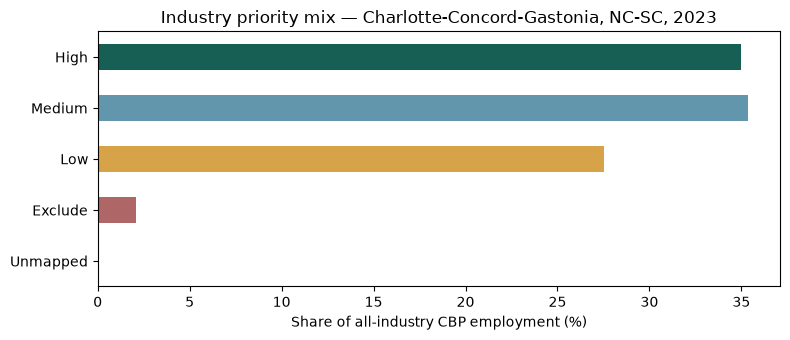

In [5]:
focus = mapped.loc[mapped.cbsa_code.eq(FOCUS_CBSA)].sort_values("cbp_employment_count", ascending=False).copy()
focus_title = focus.cbsa_title.iloc[0]
high_codes = set(priorities.loc[priorities.fit_priority.eq("High"), "naics_2digit"])
focus_high = focus.loc[focus.fit_priority.eq("High")].copy()
print(f"{focus_title} | {YEAR}")
display(focus_high[["naics_code", "label", "fit_priority", "cbp_establishments_count", "cbp_employment_count",
                    "cbp_annual_payroll_usd", "employment_share", "cbp_counties_reported_count", "expected_counties"]])
priority_order = ["High", "Medium", "Low", "Exclude", "Unmapped"]
focus_mix = focus.groupby("fit_priority").cbp_employment_count.sum(min_count=1).reindex(priority_order)
fig, ax = plt.subplots(figsize=(8, 3.5))
(focus_mix / focus.all_industry_employment.where(focus.all_industry_employment.gt(0)).iloc[0] * 100).plot.barh(
    ax=ax, color=["#175e54", "#6296ad", "#d6a348", "#ae6666", "#a0a8b2"])
ax.set(xlabel="Share of all-industry CBP employment (%)", ylabel="", title=f"Industry priority mix — {focus_title}, {YEAR}")
ax.invert_yaxis(); fig.tight_layout(); display(fig); plt.close(fig)

## 6. Industry growth and size versus growth

Employment, establishment, and nominal payroll CAGR = `(end / start) ** (1 / years) - 1`. Both endpoints must be present and positive. A missing or nonpositive endpoint yields no CAGR, never an imputed zero. Endpoint county-count changes are flagged; stable counts alone do not establish comparability. Payroll growth includes wage/price effects and is not inflation-adjusted.

The chart shows all available focus-metro sectors: employment CAGR versus current jobs, bubble area proportional to establishment count, color by priority. Missing-growth observations are omitted from the chart but retained in the table. Size/growth are descriptive opportunity context, not observed credit demand.

,naics_code,label,cbp_employment_count_start,cbp_employment_count_end,employment_cagr,establishment_cagr,payroll_cagr,endpoint_coverage_note
1250,23,Construction,62812.0,73922.0,0.041556,0.042285,0.100190,Same count; identities not verified
1251,31,Manufacturing (31-33),104199.0,110240.0,0.014189,0.003338,0.057044,Same count; identities not verified
1252,42,Wholesale Trade,60717.0,65207.0,0.017996,-0.009543,0.061131,Same count; identities not verified
1254,48,Transportation and Warehousing (48-49),57324.0,77790.0,0.079312,0.060727,0.117421,Same count; identities not verified
1257,53,Real Estate and Rental and Leasing,18882.0,22169.0,0.040937,0.047043,0.077772,Same count; identities not verified
1258,54,"Professional, Scientific, and Technical Services",70523.0,84134.0,0.045106,0.042206,0.089782,Same count; identities not verified


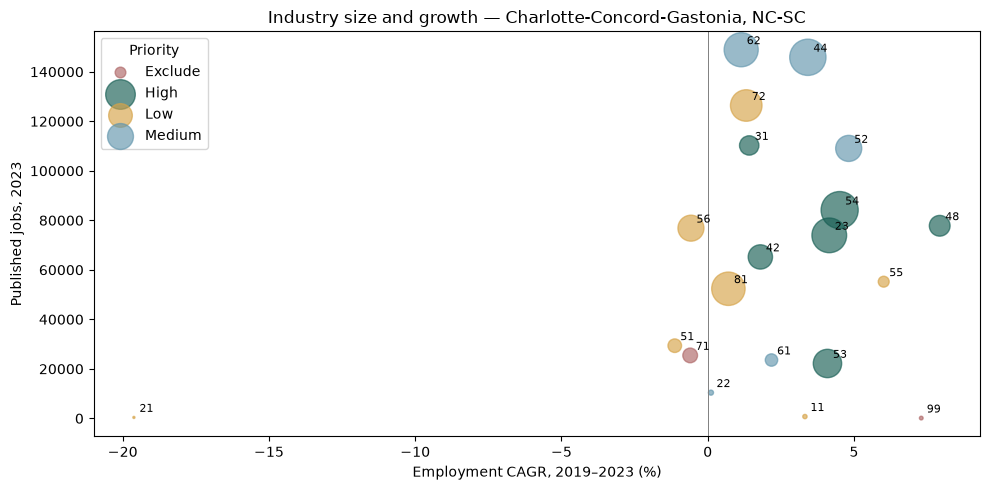

**How to read the dots:** Each label is a NAICS industry code. Horizontal position shows annual employment growth; vertical position shows published jobs. Bubble area represents establishment count; color shows the Industry Fit fit priority.

**Each dot — Charlotte-Concord-Gastonia, NC-SC, 2019–2023:**

- **11 — Agriculture, Forestry, Fishing and Hunting:** 726 jobs and 116 establishments in 2023; published employment grew 3.3% per year; **Low Fit**.
- **21 — Mining, Quarrying, and Oil and Gas Extraction:** 372 jobs and 28 establishments in 2023; published employment declined 19.6% per year; **Low Fit**. County reporting count changed between endpoints.
- **22 — Utilities:** 10,393 jobs and 162 establishments in 2023; published employment grew 0.1% per year; **Medium Fit**. County reporting count changed between endpoints.
- **23 — Construction:** 73,922 jobs and 7,500 establishments in 2023; published employment grew 4.2% per year; **High Fit**.
- **31 — Manufacturing (31-33):** 110,240 jobs and 2,341 establishments in 2023; published employment grew 1.4% per year; **High Fit**.
- **42 — Wholesale Trade:** 65,207 jobs and 3,683 establishments in 2023; published employment grew 1.8% per year; **High Fit**.
- **44 — Retail Trade (44-45):** 145,851 jobs and 8,197 establishments in 2023; published employment grew 3.4% per year; **Medium Fit**.
- **48 — Transportation and Warehousing (48-49):** 77,790 jobs and 2,680 establishments in 2023; published employment grew 7.9% per year; **High Fit**.
- **51 — Information:** 29,354 jobs and 1,150 establishments in 2023; published employment declined 1.1% per year; **Low Fit**.
- **52 — Finance and Insurance:** 109,045 jobs and 4,237 establishments in 2023; published employment grew 4.8% per year; **Medium Fit**.
- **53 — Real Estate and Rental and Leasing:** 22,169 jobs and 5,013 establishments in 2023; published employment grew 4.1% per year; **High Fit**.
- **54 — Professional, Scientific, and Technical Services:** 84,134 jobs and 8,569 establishments in 2023; published employment grew 4.5% per year; **High Fit**.
- **55 — Management of Companies and Enterprises:** 55,211 jobs and 742 establishments in 2023; published employment grew 6.0% per year; **Low Fit**.
- **56 — Administrative and Support and Waste Management and Remediation Services:** 76,824 jobs and 4,207 establishments in 2023; published employment declined 0.6% per year; **Low Fit**.
- **61 — Educational Services:** 23,568 jobs and 958 establishments in 2023; published employment grew 2.2% per year; **Medium Fit**.
- **62 — Health Care and Social Assistance:** 148,897 jobs and 7,235 establishments in 2023; published employment grew 1.1% per year; **Medium Fit**.
- **71 — Arts, Entertainment, and Recreation:** 25,425 jobs and 1,346 establishments in 2023; published employment declined 0.6% per year; **Exclude Fit**.
- **72 — Accommodation and Food Services:** 126,380 jobs and 6,197 establishments in 2023; published employment grew 1.3% per year; **Low Fit**.
- **81 — Other Services (except Public Administration):** 52,358 jobs and 6,948 establishments in 2023; published employment grew 0.7% per year; **Low Fit**.
- **99 — Unclassified Establishments:** 114 jobs and 85 establishments in 2023; published employment grew 7.3% per year; **Exclude Fit**. County reporting count changed between endpoints.

Published changes can reflect reporting/suppression differences. Stable county counts do not prove unchanged coverage. Fit colors describe the project classifications, not credit quality or measured loan demand.

In [6]:
measures = {"cbp_employment_count": "employment", "cbp_establishments_count": "establishment", "cbp_annual_payroll_usd": "payroll"}
keys = ["cbsa_code", "naics_code"]
cols = [*keys, *measures, "cbp_counties_reported_count"]
start = panel.loc[panel.year.eq(BASE_YEAR), cols]
end = panel.loc[panel.year.eq(YEAR), cols]
growth = start.merge(end, on=keys, how="outer", suffixes=("_start", "_end"), validate="one_to_one")
for raw, label in measures.items():
    a, b = growth[f"{raw}_start"], growth[f"{raw}_end"]
    valid = a.gt(0) & b.gt(0)
    growth[f"{label}_cagr"] = (b.where(valid) / a.where(valid)) ** (1 / (YEAR - BASE_YEAR)) - 1
coverage_valid = growth.cbp_counties_reported_count_start.notna() & growth.cbp_counties_reported_count_end.notna()
growth["endpoint_coverage_note"] = np.select(
    [~coverage_valid, growth.cbp_counties_reported_count_start.ne(growth.cbp_counties_reported_count_end)],
    ["Missing endpoint county count", "County count changed"], default="Same count; identities not verified")
growth = growth.merge(priorities.rename(columns={"naics_2digit": "naics_code"}), on="naics_code", how="left", validate="many_to_one")
growth["fit_priority"] = growth.fit_priority.fillna("Unmapped")
focus_growth = growth.loc[growth.cbsa_code.eq(FOCUS_CBSA)].copy()
display(focus_growth.loc[focus_growth.fit_priority.eq("High"), ["naics_code", "label", "cbp_employment_count_start",
    "cbp_employment_count_end", "employment_cagr", "establishment_cagr", "payroll_cagr", "endpoint_coverage_note"]])
colors = {"High": "#175e54", "Medium": "#6296ad", "Low": "#d6a348", "Exclude": "#ae6666", "Unmapped": "#a0a8b2"}
plot = focus_growth.dropna(subset=["employment_cagr", "cbp_employment_count_end", "cbp_establishments_count_end"])
fig, ax = plt.subplots(figsize=(10, 5))
for priority, group in plot.groupby("fit_priority"):
    ax.scatter(group.employment_cagr * 100, group.cbp_employment_count_end,
               s=group.cbp_establishments_count_end.clip(lower=0) / 12, color=colors[priority], alpha=.65, label=priority)
    for _, row in group.iterrows():
        ax.annotate(row.naics_code, (row.employment_cagr * 100, row.cbp_employment_count_end), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axvline(0, color="gray", linewidth=.7)
ax.set(xlabel=f"Employment CAGR, {BASE_YEAR}–{YEAR} (%)", ylabel=f"Published jobs, {YEAR}", title=f"Industry size and growth — {focus_title}")
ax.legend(title="Priority"); fig.tight_layout(); display(fig); plt.close(fig)

# One plain-language line for every industry dot shown above.
dot_notes = [
    "**How to read the dots:** Each label is a NAICS industry code. Horizontal position shows annual employment growth; vertical position shows published jobs. Bubble area represents establishment count; color shows the Industry Fit fit priority.",
    "",
    f"**Each dot — {focus_title}, {BASE_YEAR}–{YEAR}:**",
    "",
]
for _, row in plot.sort_values("naics_code").iterrows():
    industry = row["label"] if pd.notna(row["label"]) else f"Industry {row.naics_code}"
    rate = row.employment_cagr * 100
    trend = "grew" if rate > 0 else "declined" if rate < 0 else "was unchanged"
    change = f"{trend} {abs(rate):.1f}% per year" if rate != 0 else trend
    coverage_note = " County reporting count changed between endpoints." if row.endpoint_coverage_note == "County count changed" else ""
    dot_notes.append(
        f"- **{row.naics_code} — {industry}:** {row.cbp_employment_count_end:,.0f} jobs and "
        f"{row.cbp_establishments_count_end:,.0f} establishments in {YEAR}; published employment "
        f"{change}; **{row.fit_priority} Fit**.{coverage_note}"
    )
dot_notes.extend(["", "Published changes can reflect reporting/suppression differences. Stable county counts do not prove unchanged coverage. Fit colors describe the project classifications, not credit quality or measured loan demand."])
display(Markdown("\n".join(dot_notes)))


## 7. Industry specialization

`LQ = local sector employment / local all-industry employment ÷ benchmark sector employment / benchmark all-industry employment`.

Each industry's benchmark uses only metros with both reported sector employment and a positive all-industry denominator. The local metro is included when eligible. The table reports the benchmark sample size because it can vary by industry. This **available metro panel** is not the full national economy. LQ > 1 indicates relative concentration, not automatically stronger fit, lower risk, or excess loan demand. Missing/zero benchmark shares yield missing LQ.

,naics_code,label,fit_priority,employment_share,benchmark_share,location_quotient,benchmark_metros
1232,22,Utilities,Medium,0.008389,0.004613,1.818704,376
1239,52,Finance and Insurance,Medium,0.088019,0.050199,1.753410,387
1242,55,Management of Companies and Enterprises,Low,0.044565,0.030972,1.438894,383
1237,48,Transportation and Warehousing (48-49),High,0.062790,0.049734,1.262537,387
1235,42,Wholesale Trade,High,0.052634,0.046651,1.128239,387
1234,31,Manufacturing (31-33),High,0.088983,0.082853,1.073992,387
1246,71,"Arts, Entertainment, and Recreation",Exclude,0.020523,0.019161,1.071037,387
1233,23,Construction,High,0.059668,0.057857,1.031311,387
1243,56,Administrative and Support and Waste Managemen...,Low,0.062011,0.060281,1.028688,387
1249,99,Unclassified Establishments,Exclude,0.000092,0.000091,1.009448,274


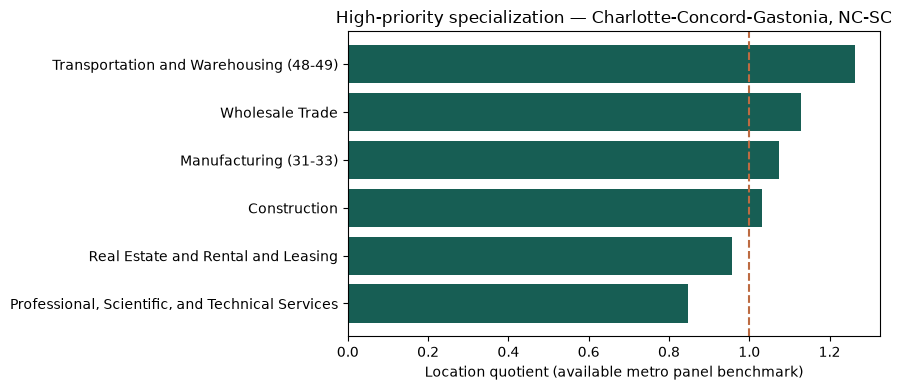

In [7]:
eligible = mapped.loc[mapped.cbp_employment_count.notna() & mapped.all_industry_employment.gt(0)]
benchmark = eligible.groupby("naics_code").agg(
    benchmark_sector_jobs=("cbp_employment_count", lambda s: s.sum(min_count=1)),
    benchmark_total_jobs=("all_industry_employment", lambda s: s.sum(min_count=1)),
    benchmark_metros=("cbsa_code", "nunique"))
benchmark["benchmark_share"] = benchmark.benchmark_sector_jobs.div(benchmark.benchmark_total_jobs)
specialization = mapped.merge(benchmark, on="naics_code", how="left", validate="many_to_one")
specialization["location_quotient"] = specialization.employment_share.div(
    specialization.benchmark_share.where(specialization.benchmark_share.gt(0)))
focus_lq = specialization.loc[specialization.cbsa_code.eq(FOCUS_CBSA)].sort_values("location_quotient", ascending=False)
display(focus_lq[["naics_code", "label", "fit_priority", "employment_share", "benchmark_share", "location_quotient", "benchmark_metros"]])
fig, ax = plt.subplots(figsize=(9, 4))
chart = focus_lq.loc[focus_lq.fit_priority.eq("High")].dropna(subset=["location_quotient"]).sort_values("location_quotient")
ax.barh(chart.label, chart.location_quotient, color="#175e54"); ax.axvline(1, color="#bd6b42", linestyle="--")
ax.set(xlabel="Location quotient (available metro panel benchmark)", title=f"High-priority specialization — {focus_title}")
fig.tight_layout(); display(fig); plt.close(fig)

## 8. Cross-metro High-priority footprint

This is a descriptive handoff, not a ranked Fit score. Employment shares use all-industry CBP employment. Sector sums retain partial observations, so interpret completeness and county coverage alongside the totals. All six sector rows can exist while parts of their county activity remain unpublished.

In [8]:
all_totals = mapped.groupby("cbsa_code").agg(
    published_sector_employment=("cbp_employment_count", lambda s: s.sum(min_count=1)),
    all_industry_employment=("all_industry_employment", "first"))
high = mapped.loc[mapped.fit_priority.eq("High")].groupby("cbsa_code").agg(
    high_employment=("cbp_employment_count", lambda s: s.sum(min_count=1)),
    high_establishments=("cbp_establishments_count", lambda s: s.sum(min_count=1)),
    high_sectors_with_employment=("cbp_employment_count", "count"),
    high_min_county_coverage=("county_coverage_fraction", "min"))
summary = names.merge(all_totals, on="cbsa_code", how="inner", validate="one_to_one").merge(high, on="cbsa_code", how="left", validate="one_to_one")
present = mapped.loc[mapped.fit_priority.eq("High") & mapped.cbp_employment_count.notna()].groupby("cbsa_code").naics_code.agg(set)
summary["missing_high_sectors"] = summary.cbsa_code.map(lambda k: "; ".join(sorted(high_codes - present.get(k, set()))))
summary["high_employment_share"] = summary.high_employment.div(summary.all_industry_employment.where(summary.all_industry_employment.gt(0)))
summary["all_high_sectors_have_employment"] = summary.high_sectors_with_employment.eq(len(high_codes))
summary["year"] = YEAR
print(f"{summary.all_high_sectors_have_employment.sum()}/{len(summary)} metros have employment for all {len(high_codes)} High sectors.")
display(summary.loc[summary.cbsa_code.eq(FOCUS_CBSA)])

387/387 metros have employment for all 6 High sectors.


,cbsa_code,cbsa_title,published_sector_employment,all_industry_employment,high_employment,high_establishments,high_sectors_with_employment,high_min_county_coverage,missing_high_sectors,high_employment_share,all_high_sectors_have_employment,year
63,16740,"Charlotte-Concord-Gastonia, NC-SC",1237980.0,1238884.0,433462.0,29786,6,1.0,,0.349881,True,2023


## 9. Selected comparison markets

These are illustrative comparison metros, not a statistically selected bank peer group. All use the same reference years, classification lookup, and denominators. Compare industry scale, employment share, specialization, and growth; missing values remain visible. Geography, metro size, and county reporting can differ substantially.

In [9]:
peer_codes = list(dict.fromkeys([FOCUS_CBSA, *PEER_CBSAS]))
print("Requested comparison codes absent from snapshot:", sorted(set(peer_codes) - set(mapped.cbsa_code)))
peer_summary = summary.loc[summary.cbsa_code.isin(peer_codes)].sort_values("cbsa_title")
peer_detail = specialization.loc[specialization.cbsa_code.isin(peer_codes) & specialization.fit_priority.eq("High"),
    ["cbsa_code", "cbsa_title", "naics_code", "label", "cbp_employment_count", "employment_share", "location_quotient", "county_coverage_fraction"]].merge(
    growth[["cbsa_code", "naics_code", "employment_cagr", "endpoint_coverage_note"]], on=["cbsa_code", "naics_code"], how="left", validate="one_to_one")
display(peer_summary[["cbsa_title", "high_employment", "high_establishments", "high_employment_share", "all_high_sectors_have_employment", "high_min_county_coverage"]])
display(peer_detail.pivot(index="label", columns="cbsa_title", values="location_quotient").round(2))

Requested comparison codes absent from snapshot: []


,cbsa_title,high_employment,high_establishments,high_employment_share,all_high_sectors_have_employment,high_min_county_coverage
18,"Atlanta-Sandy Springs-Roswell, GA",1000429.0,67712,0.371560,True,1.000000
63,"Charlotte-Concord-Gastonia, NC-SC",433462.0,29786,0.349881,True,1.000000
84,"Dallas-Fort Worth-Arlington, TX",1344741.0,75534,0.374085,True,1.000000
246,"Nashville-Davidson--Murfreesboro--Franklin, TN",316139.0,17828,0.312178,True,0.928571
284,"Raleigh-Cary, NC",208711.0,16666,0.337988,True,1.000000
343,"Tampa-St. Petersburg-Clearwater, FL",391785.0,37784,0.304132,True,1.000000


cbsa_title,"Atlanta-Sandy Springs-Roswell, GA","Charlotte-Concord-Gastonia, NC-SC","Dallas-Fort Worth-Arlington, TX","Nashville-Davidson--Murfreesboro--Franklin, TN","Raleigh-Cary, NC","Tampa-St. Petersburg-Clearwater, FL"
label,,,,,,
Construction,0.94,1.03,1.05,0.94,1.24,1.14
Manufacturing (31-33),0.73,1.07,0.95,0.95,0.56,0.65
"Professional, Scientific, and Technical Services",1.18,0.85,1.06,0.72,1.50,1.18
Real Estate and Rental and Leasing,1.25,0.96,1.24,0.98,0.94,1.08
Transportation and Warehousing (48-49),1.66,1.26,1.48,1.29,0.49,0.60
Wholesale Trade,1.19,1.13,1.14,0.83,1.23,0.85


## 10. Coverage and missingness through time

Build an explicit metro × year × expected sector grid. This makes absent rows visible instead of treating a missing sector as zero. Reported county coverage is a publication diagnostic; it does not measure the size of any undercount. Negative growth with a coverage change should be investigated before economic interpretation. Even stable counts can hide changes in county identities or suppression.

In [10]:
coverage_years = sorted(y for y in panel.year.unique() if BASE_YEAR <= y <= YEAR)
expected_sectors = sorted(set(panel.naics_code))
grid = pd.MultiIndex.from_product([peer_codes, coverage_years, expected_sectors], names=["cbsa_code", "year", "naics_code"]).to_frame(index=False)
coverage_audit = grid.merge(panel, on=["cbsa_code", "year", "naics_code"], how="left", validate="one_to_one", indicator=True)
coverage_audit["row_present"] = coverage_audit.pop("_merge").eq("both")
coverage_audit = coverage_audit.join(expected, on="cbsa_code")
coverage_audit["county_coverage_fraction"] = coverage_audit.cbp_counties_reported_count.div(coverage_audit.expected_counties)
coverage_audit["employment_missing"] = coverage_audit.cbp_employment_count.isna()
coverage_audit["payroll_missing"] = coverage_audit.cbp_annual_payroll_usd.isna()
focus_coverage = coverage_audit.loc[coverage_audit.cbsa_code.eq(FOCUS_CBSA)]
display(focus_coverage.pivot(index="naics_code", columns="year", values="county_coverage_fraction").round(2))
coverage_summary = coverage_audit.groupby(["cbsa_code", "year"], as_index=False).agg(
    expected_sector_rows=("naics_code", "size"), published_rows=("row_present", "sum"),
    missing_employment=("employment_missing", "sum"), missing_payroll=("payroll_missing", "sum"))
display(coverage_summary.merge(names, on="cbsa_code", how="left", validate="many_to_one"))

year,2019,2020,2021,2022,2023
naics_code,,,,,
11,1.00,0.91,1.00,1.00,1.00
21,0.45,0.45,0.45,0.36,0.36
22,1.00,1.00,1.00,0.91,0.91
23,1.00,1.00,1.00,1.00,1.00
31,1.00,1.00,1.00,1.00,1.00
42,1.00,1.00,1.00,1.00,1.00
44,1.00,1.00,1.00,1.00,1.00
48,1.00,1.00,1.00,1.00,1.00
51,1.00,1.00,1.00,1.00,1.00


,cbsa_code,year,expected_sector_rows,published_rows,missing_employment,missing_payroll,cbsa_title
0,12060,2019,20,20,0,0,"Atlanta-Sandy Springs-Roswell, GA"
1,12060,2020,20,20,0,0,"Atlanta-Sandy Springs-Roswell, GA"
2,12060,2021,20,20,0,0,"Atlanta-Sandy Springs-Roswell, GA"
3,12060,2022,20,20,0,0,"Atlanta-Sandy Springs-Roswell, GA"
4,12060,2023,20,20,0,0,"Atlanta-Sandy Springs-Roswell, GA"
5,16740,2019,20,20,0,0,"Charlotte-Concord-Gastonia, NC-SC"
6,16740,2020,20,20,0,0,"Charlotte-Concord-Gastonia, NC-SC"
7,16740,2021,20,20,0,0,"Charlotte-Concord-Gastonia, NC-SC"
8,16740,2022,20,20,0,0,"Charlotte-Concord-Gastonia, NC-SC"
9,16740,2023,20,20,0,0,"Charlotte-Concord-Gastonia, NC-SC"


## 11. Priority sensitivity: High versus High + Medium

Keep the original classifications fixed and compare two inclusion scenarios. This is the change in the **included industry's employment footprint**, not a new score, ranking. The incremental share represents the Medium sectors added. Report observed versus expected sector counts to expose missing inputs. Public administration 92 is Low, so its absence does not enter these two scenarios.

In [11]:
sensitivity_parts = []
for scenario, included in [("High only", ["High"]), ("High + Medium", ["High", "Medium"])]:
    subset = mapped.loc[mapped.fit_priority.isin(included)]
    expected_codes = set(priorities.loc[priorities.fit_priority.isin(included), "naics_2digit"])
    part = subset.groupby("cbsa_code").agg(
        included_employment=("cbp_employment_count", lambda s: s.sum(min_count=1)),
        observed_sector_count=("cbp_employment_count", "count"))
    part = all_totals[["all_industry_employment"]].join(part)
    part["expected_sector_count"] = len(expected_codes)
    part["complete_sector_observations"] = part.observed_sector_count.eq(len(expected_codes))
    part["employment_share"] = part.included_employment.div(part.all_industry_employment.where(part.all_industry_employment.gt(0)))
    part["scenario"] = scenario
    sensitivity_parts.append(part.reset_index())
sensitivity = pd.concat(sensitivity_parts, ignore_index=True).merge(names, on="cbsa_code", how="left", validate="many_to_one")
sensitivity_compare = sensitivity.pivot(index=["cbsa_code", "cbsa_title"], columns="scenario", values="employment_share").reset_index()
sensitivity_compare["medium_increment_percentage_points"] = (sensitivity_compare["High + Medium"] - sensitivity_compare["High only"]) * 100
display(sensitivity.loc[sensitivity.cbsa_code.eq(FOCUS_CBSA)])
display(sensitivity_compare.loc[sensitivity_compare.cbsa_code.isin(peer_codes)])

,cbsa_code,all_industry_employment,included_employment,observed_sector_count,expected_sector_count,complete_sector_observations,employment_share,scenario,cbsa_title
63,16740,1238884.0,433462.0,6,6,True,0.349881,High only,"Charlotte-Concord-Gastonia, NC-SC"
450,16740,1238884.0,871216.0,11,11,True,0.703226,High + Medium,"Charlotte-Concord-Gastonia, NC-SC"


scenario,cbsa_code,cbsa_title,High + Medium,High only,medium_increment_percentage_points
18,12060,"Atlanta-Sandy Springs-Roswell, GA",0.687242,0.371560,31.568241
63,16740,"Charlotte-Concord-Gastonia, NC-SC",0.703226,0.349881,35.334543
84,19100,"Dallas-Fort Worth-Arlington, TX",0.697909,0.374085,32.382428
246,34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",0.668357,0.312178,35.617944
284,39580,"Raleigh-Cary, NC",0.670239,0.337988,33.225157
343,45300,"Tampa-St. Petersburg-Clearwater, FL",0.711134,0.304132,40.700260


## 12. Interpretation and calculation checks

The section explains that industry size, growth, and concentration can help identify markets for further research. 
The calculation checks confirm that:
- Every industry has a valid Fit classification.
- Utilities 22, healthcare 62, and finance 52 are Medium. Sectors 56 and 81 remain Low.
- Metro–industry records are not duplicated.
- Missing or invalid employment totals produce missing shares.
- Growth calculations contain no infinite values.
- Industry-specialization calculations are internally consistent.
- Adding Medium industries does not reduce the included employment share.

Finally, it summarizes the selected metro’s High-priority employment share and fastest-growing High-priority industry.

In [12]:
assert mapped.fit_priority.isin(["High", "Medium", "Low", "Exclude", "Unmapped"]).all()
assert priorities.set_index("naics_2digit").loc[["22", "52", "62"], "fit_priority"].eq("Medium").all()
assert priorities.set_index("naics_2digit").loc[["56", "81"], "fit_priority"].eq("Low").all()
assert not mapped.duplicated(["cbsa_code", "naics_code"]).any()
assert not growth.duplicated(["cbsa_code", "naics_code"]).any()
assert mapped.loc[mapped.all_industry_employment.le(0) | mapped.all_industry_employment.isna(), "employment_share"].isna().all()
assert np.isfinite(growth[["employment_cagr", "establishment_cagr", "payroll_cagr"]].stack().dropna()).all()
# LQ's employment-weighted average must equal one for each positive benchmark industry.
valid_lq = specialization.dropna(subset=["location_quotient"]).copy()
for _, group in valid_lq.groupby("naics_code"):
    assert np.isclose(np.average(group.location_quotient, weights=group.all_industry_employment), 1.0)
assert sensitivity_compare.medium_increment_percentage_points.dropna().ge(-1e-9).all()
print("Calculation and reconciliation checks passed.")
s = summary.loc[summary.cbsa_code.eq(FOCUS_CBSA)].iloc[0]
leaders = focus_growth.loc[focus_growth.fit_priority.eq("High")].dropna(subset=["employment_cagr"]).sort_values("employment_cagr", ascending=False)
display(Markdown(f"**{focus_title}, {YEAR}:** the six High-priority industries account for **{s.high_employment_share:.1%}** of all-industry CBP employment. "
    f"The largest employment CAGR among the available High industries is **{leaders.iloc[0]['label']} ({leaders.iloc[0].employment_cagr:.1%})** over {BASE_YEAR}–{YEAR}. "
    "Review reporting coverage alongside these observations. These are descriptive industry-fit inputs, not an entry recommendation."))

Calculation and reconciliation checks passed.


**Charlotte-Concord-Gastonia, NC-SC, 2023:** the six High-priority industries account for **35.0%** of all-industry CBP employment. The largest employment CAGR among the available High industries is **Transportation and Warehousing (48-49) (7.9%)** over 2019–2023. Review reporting coverage alongside these observations. These are descriptive industry-fit inputs, not an entry recommendation.

## 13. Optional CSV and Excel handoff

Set `EXPORT = True` in setup and Run All. Outputs are confined to `outputs/industry_fit/notebook/`; existing files with these names are replaced on export. Existing standalone Utilities outputs are untouched. Exports include evidence, growth, specialization, peer details, coverage, sensitivity, and input fingerprints.

In [13]:
if EXPORT:
    import json
    OUT.mkdir(parents=True, exist_ok=True)
    tables = {"Evidence": evidence, "Sector detail": mapped, "Focus metro": focus,
              "Growth": growth, "Specialization": specialization, "Metro footprint": summary,
              "Peer detail": peer_detail, "Coverage": coverage_audit, "Sensitivity": sensitivity,
              "Reconciliation": reconciliation, "Sources": provenance}
    for label, frame in tables.items():
        frame.to_csv(OUT / f"industry_fit_{label.lower().replace(' ', '_')}_{YEAR}.csv", index=False)
    with pd.ExcelWriter(OUT / f"Industry_Fit_{YEAR}.xlsx", engine="openpyxl") as writer:
        for label, frame in tables.items():
            frame.to_excel(writer, sheet_name=label, index=False)
    (OUT / "run_metadata.json").write_text(json.dumps({
        "task": "Industry Fit", "year": YEAR, "base_year": BASE_YEAR, "focus_cbsa": FOCUS_CBSA,
        "illustrative_peer_cbsas": peer_codes, "numeric_fit_score": False,
        "primary_denominator": "msa_year.cbp_employment_count",
        "lq_benchmark": "Available metros with reported industry employment and positive all-industry employment; varies by industry",
        "inputs": provenance.to_dict(orient="records"),
    }, indent=2))
    print(f"Exported {len(tables)} tables and Excel workbook to {OUT}")
else:
    print("Exports disabled. Set EXPORT = True to generate CSV and Excel handoffs.")

Exported 11 tables and Excel workbook to /Users/jainesh/Downloads/BankUnited/bankunited-market-expansion/outputs/industry_fit/notebook
